# Cell cycle in a paired RNA and imaging screen

The Element Cytos assay images Cell Painting stains and four protein stains, reads the CRISPR guide, and sequences
3' RNA, all in the same cells. Because the RNA of every imaged cell is known, an RNA cell-cycle clock gives a
reference that imaging screens usually lack, and we can check what mantispy's cell-cycle tools get from the imaging
against it.

The screen knocks out six genes in A549 cells (CTNNB1, GSK3B, IL1R1, OR1I1, SMAD7 and TGFBR2), with four guides per
gene and four non-targeting (NTC) guides, in 12 wells on one plate. Six wells were stimulated with TNF-alpha and six
were left at baseline. OR1I1 is an olfactory receptor that A549 cells do not express, so it should behave like a
control.

mantispy's cell-cycle tools give more the more you measure. With a DNA stain alone,
{func}`~mantispy.tl.fit_cell_cycle` and {func}`~mantispy.tl.project_cell_cycle` give phases, a position within S and
the uncertainty of every cell. With informative non-DNA channels, {func}`~mantispy.tl.phase_order` adds an
experimental order inside a phase. With a second measurement of the cycle in the same cells, such as RNA here, you can
calibrate and check the DNA model. This case study is about the last situation. It compares the DNA stain with the RNA
clock, shows why mantispy refuses to fit this stain, and calibrates the DNA model from RNA on some wells to score it on
the others. It then asks which morphology features and which knockouts follow the clock.

The staged file is a MuData object with imaging, RNA and guide modalities. We read the shared cell metadata and the
imaging modality with h5py and anndata. The RNA clock was fitted once with CycleVI and stored on the cells, together
with the S and G2M scores from {func}`scanpy.tl.score_genes_cell_cycle`.

In [1]:
import hashlib
import random
import warnings
from pathlib import Path

import anndata as ad
import h5py
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pooch
from anndata.io import read_elem
from scipy import optimize, stats

import mantispy as mt

plt.rcParams["figure.dpi"] = 110
WELL = ["Metadata_Plate", "Metadata_Well"]
PHASES = ["G1", "S", "G2M"]

URL = "https://exampledata.scverse.org/sbi2-cytodata/multiomics/cytos_multiomics_cycle_v1.h5mu"
SHA = "sha256:1ea59dec251c2926c33379cbb0ad14bef688aad4b32a90175e1ecd5cb2282230"
CACHE = Path(pooch.os_cache("mantispy-casestudies"))
path = pooch.retrieve(URL, known_hash=SHA, fname="cytos_multiomics_cycle_v1.h5mu", path=CACHE)
with h5py.File(path, "r") as f:
    obs = read_elem(f["obs"])
    img = read_elem(f["mod/imaging"])
assert (img.obs_names == obs.index).all()
img.obs = obs.copy()
print(img)
print(
    {
        name: sorted(group.astype(str).unique())
        for name, group in obs.groupby("condition", observed=True)["Metadata_Well"]
    }
)
print("median RNA counts per cell:", int(obs["rna_total_counts"].median()))
obs.groupby("target_gene", observed=True).agg(cells=("guide", "size"), guides=("guide", "nunique")).T

AnnData object with n_obs × n_vars = 206091 × 1131
    obs: 'Well', 'Cell', 'tile_id', 'condition', 'guide', 'target_gene', 'guide_confidence', 'guide_assigned', 'rna_total_counts', 'rna_n_genes', 'rna_pct_mt', 'qc_low_rna', 'qc_guide_unassigned', 'qc_spatial_artifact', 'qc_imaging_nan', 'qc_no_nucleus', 'Metadata_Plate', 'Metadata_Well', 'Metadata_ImageID', 'Metadata_ObjectType', 'Metadata_ObjectNumber', 'Metadata_Perturbation', 'Metadata_Row', 'Metadata_Col', 'Metadata_Control_Type', 'Metadata_Control', 'qc_n_nan_features', 'qc_nan_fraction', 'qc_is_border', 'qc_area_outlier', 'qc_fail', 'qc_outlier', 'qc_outlier_score', 'cycle_position_deg', 'cycle_radius', 'S_score', 'G2M_score', 'phase_scanpy'
    var: 'channel', 'modality', 'feature', 'object', 'feature_group', 'scale', 'angle', 'gray_levels', 'radial_bin', 'params', 'is_feature', 'feature_kind', 'qc_n_nan', 'qc_variance', 'qc_n_unique', 'degenerate_scale', 'selected', 'clock_rank', 'clock_rank_nonredundant', 'clock_redundancy_gr

{'TNFa': ['A2', 'B2', 'C2', 'D1', 'E1', 'F1'], 'baseline': ['A1', 'B1', 'C1', 'D2', 'E2', 'F2']}
median RNA counts per cell: 1470


target_gene,CTNNB1,GSK3B,IL1R1,NTC,OR1I1,SMAD7,TGFBR2
cells,45348,33952,13727,26943,68925,10175,7021
guides,4,4,4,4,4,4,4


## The RNA clock

CycleVI places each cell on a circle from its RNA counts, but its angle has no fixed start or direction. We fix both
from the cell-cycle scores, in three steps:

1. The clock runs in the direction in which the G2M score peaks after the S score.
2. Angle 0 is where the mean G2M score falls fastest. G2M transcripts are degraded as a cell divides, so 0 marks the
   start of G1.
3. The RNA phases are the arcs G1, S and G2M, in that order from 0, that agree best with the per-cell phase calls
   from the scores.

The angle is not time, because CycleVI does not spread cells evenly in time. The RNA position converts the angle the
way mantispy converts DNA content. Cells are ranked along the clock, and each rank is mapped through the age
distribution of a growing population {cite:p}`Kafri_2013`. Position 0 is the start of G1 and 1 is division, as in
{func}`~mantispy.tl.project_cell_cycle`.

In [2]:
def harmonic_peak(values, angle):
    """Angle at which a value peaks along a circle, from its first Fourier component."""
    return float(np.angle(np.mean((values - values.mean()) * np.exp(1j * angle))))


def orient(angle, s_score, g2m_score):
    """Turn a CycleVI angle into a clock that runs from S to G2M and starts where the G2M score collapses."""
    direction = np.sign(np.angle(np.exp(1j * (harmonic_peak(g2m_score, angle) - harmonic_peak(s_score, angle)))))
    angle = (direction * angle) % (2 * np.pi)
    bins = (angle // np.deg2rad(10)).astype(int)
    profile = pd.Series(g2m_score).groupby(bins).mean().reindex(range(36)).to_numpy()
    start = np.deg2rad(10) * (np.argmin(np.roll(profile, -1) - profile) + 1)
    return (angle - start) % (2 * np.pi)


def best_arcs(angle, labels, n_bins=72):
    """Boundaries of the contiguous arcs G1, S, G2M from angle 0 that agree best with per-cell phase labels."""
    bins = np.minimum((angle / (2 * np.pi) * n_bins).astype(int), n_bins - 1)
    counts = np.stack([np.bincount(bins[labels == p], minlength=n_bins) for p in PHASES], axis=1)
    cum = np.vstack([np.zeros(3), np.cumsum(counts, axis=0)])
    first, second = np.meshgrid(np.arange(n_bins + 1), np.arange(n_bins + 1), indexing="ij")
    agree = cum[first, 0] + cum[second, 1] - cum[first, 1] + cum[-1, 2] - cum[second, 2]
    agree[second < first] = -1
    b1, b2 = np.unravel_index(np.argmax(agree), agree.shape)
    return 2 * np.pi * np.array([b1, b2]) / n_bins


def age(fraction):
    """Cycle position of the cell at a cumulative fraction of an exponentially growing population."""
    return -np.log2(1 - np.clip(fraction, 0, 1) / 2)


def circular_correlation(a, b):
    """Jammalamadaka and SenGupta's correlation between two angles."""
    sa, sb = np.sin(a - stats.circmean(a)), np.sin(b - stats.circmean(b))
    return float((sa * sb).sum() / np.sqrt((sa**2).sum() * (sb**2).sum()))


def circular_error(a, b):
    """Absolute difference between two angles, in degrees."""
    return np.abs(np.rad2deg(np.angle(np.exp(1j * (a - b)))))


clock = orient(np.deg2rad(obs["cycle_position_deg"].to_numpy()), obs["S_score"].to_numpy(), obs["G2M_score"].to_numpy())
s_start, g2m_start = best_arcs(clock, obs["phase_scanpy"].astype(str).to_numpy())
rna_phase = np.select([clock < s_start, clock < g2m_start], ["G1", "S"], "G2M")
rna_position = age(stats.rankdata(clock) / clock.size - 0.5 / clock.size)
img.obs["rna_clock"], img.obs["rna_position"] = clock, rna_position
img.obs["rna_phase"] = pd.Categorical(rna_phase, categories=PHASES)
shares = img.obs["rna_phase"].value_counts(normalize=True)[PHASES]
print(
    "RNA phase shares:",
    shares.round(3).to_dict(),
    "| per-cell scanpy calls:",
    obs["phase_scanpy"].value_counts(normalize=True).round(3).to_dict(),
)
print("RNA phase edges on the position scale:", np.round(age(np.r_[0, np.cumsum(shares)]), 3))

RNA phase shares: {'G1': 0.186, 'S': 0.455, 'G2M': 0.359} | per-cell scanpy calls: {'G2M': 0.524, 'S': 0.381, 'G1': 0.095}
RNA phase edges on the position scale: [-0.     0.141  0.558  1.   ]


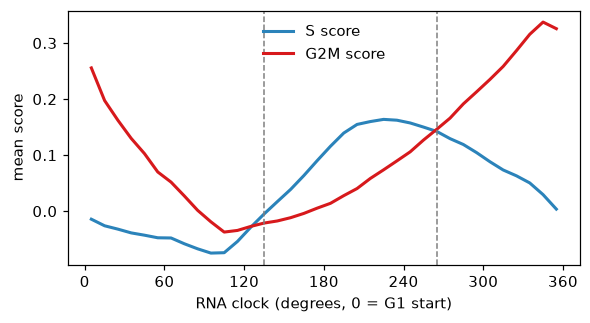

In [3]:
centres = np.arange(5, 360, 10)
bins = (np.rad2deg(clock) // 10).astype(int)
profile = obs.groupby(bins)[["S_score", "G2M_score"]].mean()
fig, ax = plt.subplots(figsize=(6, 3))
for column, colour in (("S_score", "#2b83ba"), ("G2M_score", "#d7191c")):
    ax.plot(centres, profile[column], color=colour, lw=2, label=column.replace("_", " "))
for edge in np.rad2deg([s_start, g2m_start]):
    ax.axvline(edge, color="0.5", ls="--", lw=1)
ax.set(xlabel="RNA clock (degrees, 0 = G1 start)", ylabel="mean score", xticks=range(0, 361, 60))
ax.legend(frameon=False)
plt.show()

The arcs put 19% of cells in G1, 46% in S and 36% in G2M. The per-cell calls put only 10% of cells in G1, because a
cell is called G1 only when both of its scores are below zero, and with about 1,500 counts per cell few cells meet
that. The arcs follow transcription, not DNA. As the next section shows, the RNA S arc begins well before the DNA
content starts to rise, which fits S-phase genes being switched on before replication starts, although noise in the
clock could add to the gap.

### Where the clock comes from

The staged angle comes from one CycleVI run made for the hackathon this dataset was prepared for. CycleVI was
fitted on the raw RNA counts of every cell in all 12 wells, with the genes detected in at least 1% of cells, no batch
covariate, the default architecture and 400 epochs. The fit read no imaging feature. The run's seed was not recorded,
and its notes say training had not converged, so the order of events along the clock is better supported than exact
angles. The fit saw the held-out wells used below, but only their RNA, so it can't have been tuned on the imaging.

To check that the clock is a property of the RNA and not of that one run, we refitted CycleVI on the same counts in a
separate environment, since CycleVI is not a mantispy dependency. The refit used cyclevi 0.2.1, the same cells and
genes, seed 0, the default architecture and 400 epochs on a GPU, and it read no imaging feature. Its validation loss
stopped improving after about 250 epochs. The script is below, and its angles are cached next to the data.

```python
import anndata as ad, h5py, numpy as np, pandas as pd, scvi
from anndata.io import read_elem
from cyclevi import CycleVI
from cyclevi.prepare import compute_phase_initialization

with h5py.File(path, "r") as f:
    counts = read_elem(f["mod/rna/X"])
    genes = read_elem(f["mod/rna/var"]).index.astype(str)
    cells = read_elem(f["obs"]).index.astype(str)
detected = np.asarray((counts > 0).mean(0)).ravel() >= 0.01
rna = ad.AnnData(counts[:, detected].astype(np.float32), obs=pd.DataFrame(index=cells))
rna.var_names = genes[detected]
scvi.settings.seed = 0
compute_phase_initialization(rna, gene_id_type="symbol")
CycleVI.setup_anndata(
    rna, layer="counts", cycle_initiation_label_key="phase", cycle_initiation_angle_key="cycle_angle_uniform"
)
model = CycleVI(rna)
model.train(max_epochs=400, batch_size=128, plan_kwargs={"lr": 1e-3}, accelerator="gpu")
z = model.get_latent_representation(rna)
angle = pd.DataFrame({"cycle_angle": np.arctan2(z[:, 1], z[:, 0])}, index=rna.obs_names)
angle.to_csv(CACHE / "cytos_cyclevi_rerun.csv.gz")
```

In [4]:
fresh = pd.read_csv(CACHE / "cytos_cyclevi_rerun.csv.gz", index_col=0).reindex(obs.index)["cycle_angle"].to_numpy()
fresh_clock = orient(fresh, obs["S_score"].to_numpy(), obs["G2M_score"].to_numpy())
fresh_position = age(stats.rankdata(fresh_clock) / clock.size - 0.5 / clock.size)
fresh_phase = np.select([fresh_clock < s_start, fresh_clock < g2m_start], ["G1", "S"], "G2M")
print("circular correlation, staged against refit:", round(circular_correlation(clock, fresh_clock), 3))
print(
    "median difference in RNA position (share of the cycle):",
    round(float(np.median(np.abs(rna_position - fresh_position))), 3),
)
print("cells with the same RNA phase, using the staged arcs:", round(float(np.mean(fresh_phase == rna_phase)), 3))

circular correlation, staged against refit: 0.972
median difference in RNA position (share of the cycle): 0.014
cells with the same RNA phase, using the staged arcs: 0.919


The refit agrees with the staged clock. The circular correlation between the two angles is 0.97, the median cell
moves by 1.4% of the cycle, and 92% of cells keep their RNA phase. Everything below uses the staged angle, so the
notebook runs without CycleVI.

## DNA content against the RNA clock

The imaging has a nuclear stain, the Nucleus channel. Its integrated intensity is the background-subtracted mean
intensity in the nucleus times the nuclear area. {func}`~mantispy.tl.dna_content` turns it into doublings of each
well's G1 peak, found on the NTC cells.

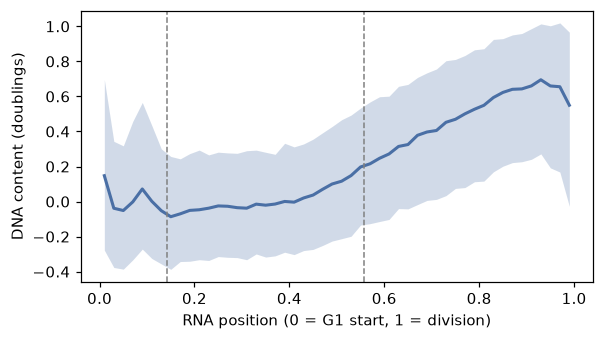

median DNA content by RNA phase: {'G1': 0.01, 'S': 0.0, 'G2M': 0.47}
rise of the median along the RNA clock (doublings): 0.78
median width of the middle half (doublings): 0.7


In [5]:
raw = pd.DataFrame(
    img.layers["raw"][:, [img.var_names.get_loc(n) for n in ("Nucleus_Nuclear", "Bkg_Nucleus_Nuclear", "NuclearArea")]],
    columns=["nucleus", "background", "area"],
    index=img.obs_names,
)
cells = ad.AnnData(
    ((raw["nucleus"] - raw["background"]) * raw["area"]).to_numpy()[:, None],
    obs=img.obs[
        [
            *WELL,
            "Metadata_ImageID",
            "Metadata_Control_Type",
            "condition",
            "guide",
            "target_gene",
            "rna_position",
            "rna_phase",
        ]
    ].copy(),
    var=pd.DataFrame(index=["dna_readout"]),
)
mt.tl.dna_content(cells, dna_feature="dna_readout", reference="negcon")
dna = cells.obs["Metadata_DNAContent"].to_numpy()

edges = np.linspace(0, 1, 51)
which = np.digitize(rna_position, edges[1:-1])
curve = pd.Series(dna).groupby(which).quantile([0.25, 0.5, 0.75]).unstack()
fig, ax = plt.subplots(figsize=(6, 3.2))
ax.fill_between((edges[:-1] + edges[1:]) / 2, curve[0.25], curve[0.75], color="#4a6fa5", alpha=0.25, lw=0)
ax.plot((edges[:-1] + edges[1:]) / 2, curve[0.5], color="#4a6fa5", lw=2)
for edge in age(np.cumsum(shares)[:2]):
    ax.axvline(edge, color="0.5", ls="--", lw=1)
ax.set(xlabel="RNA position (0 = G1 start, 1 = division)", ylabel="DNA content (doublings)")
plt.show()
by_phase = cells.obs.groupby("rna_phase", observed=True)["Metadata_DNAContent"].median()
print("median DNA content by RNA phase:", by_phase.round(2).to_dict())
print("rise of the median along the RNA clock (doublings):", round(float(curve[0.5].max() - curve[0.5].min()), 2))
print("median width of the middle half (doublings):", round(float((curve[0.75] - curve[0.25]).median()), 2))

The median DNA content stays near zero through the RNA G1 arc and the first half of the S arc. It rises from the
middle of S, reaches about 0.7 doublings just before division, and falls in the last bin. The shape is the cell cycle,
but it is a median over many cells. The shaded band holds the middle half of the cells at each position and is about as wide as the whole rise,
so a single cell's DNA content says little about where it is.

{func}`~mantispy.pl.cell_cycle` draws the DNA content of every well, coloured by RNA phase. Every well has one broad
peak, and the G2M cells sit a little to the right of the G1 cells instead of in a second peak one doubling higher.

0.5% of cells lie outside -1.5 to 2.5 doublings and are left out of the plot


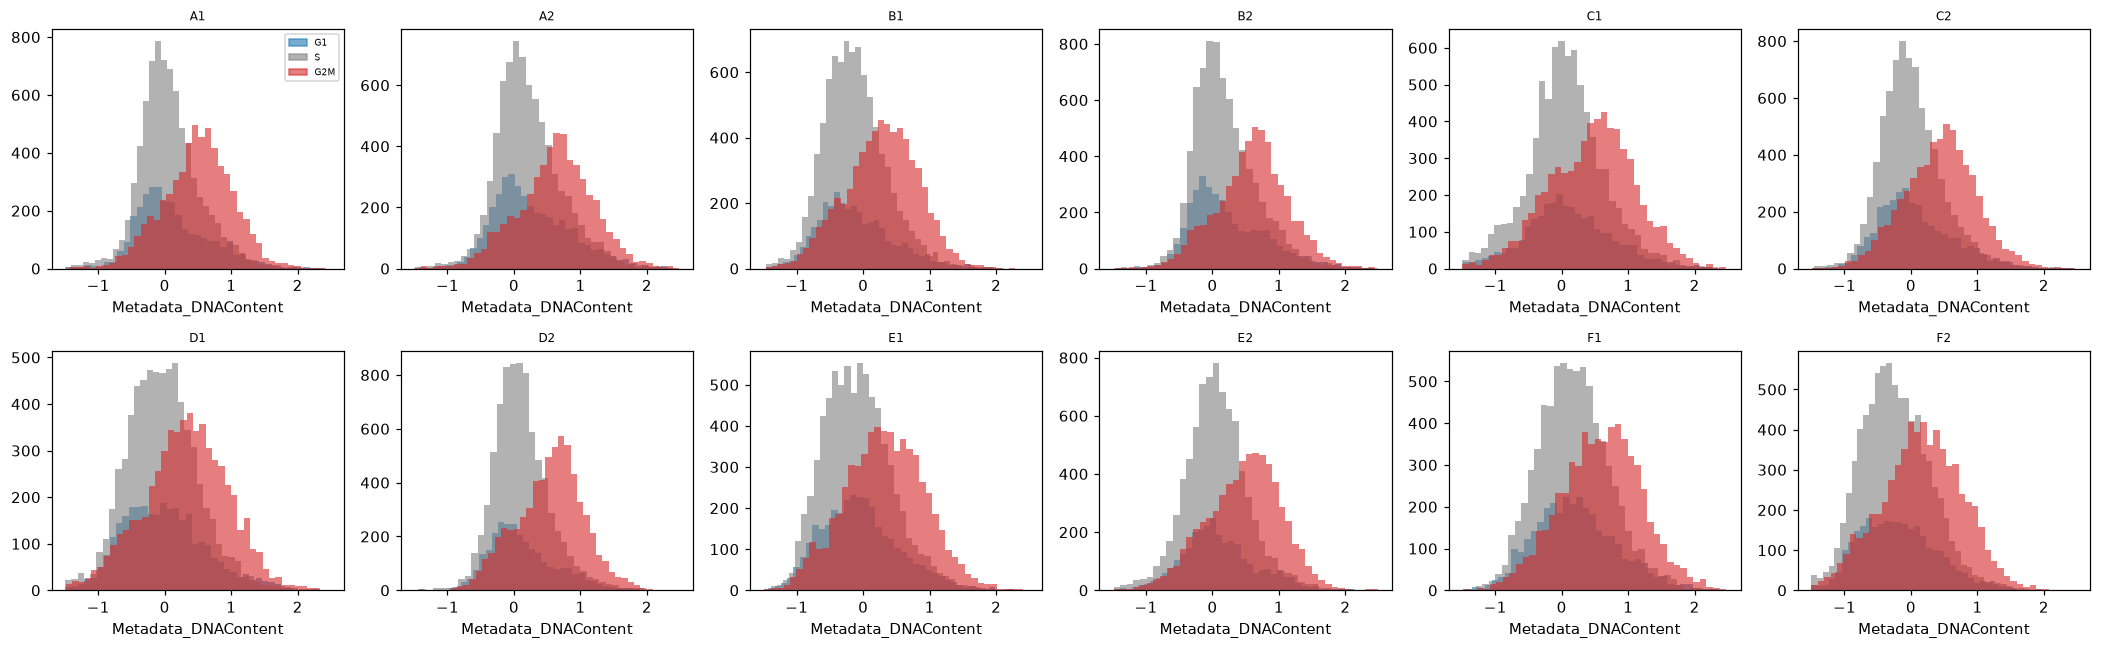

In [6]:
shown = (dna > -1.5) & (dna < 2.5)
print(f"{1 - shown.mean():.1%} of cells lie outside -1.5 to 2.5 doublings and are left out of the plot")
mt.pl.cell_cycle(cells[shown], "Metadata_DNAContent", by="Metadata_Well", key="rna_phase", ncols=6)
plt.show()

## mantispy refuses to fit this stain

{func}`~mantispy.tl.fit_cell_cycle` first checks that the reference cells show a 2N peak, a separate 4N peak and S
cells between them. Here the check fails, the function warns, and {func}`~mantispy.tl.project_cell_cycle` would give
NaN for every cell. The check finds no 4N peak (`is_peak` is False), and the density between the peaks is higher
than at the place where the 4N peak should be (`valley_ratio` is 1.09, where the check asks for at most 0.9). Phases
fitted to a histogram with one peak would be made up, so refusing is the correct result.

In [7]:
mt.tl.fit_cell_cycle(cells)
cells.uns["mantispy"]["cell_cycle"]["check"]

fit_cell_cycle: the reference does not show separate 2N and 4N peaks with S cells between them {'is_peak': False, 'peak_ratio': 0.666, 'valley_ratio': 1.089, 's_floor': 0.911, 's_share': 0.237}; project_cell_cycle will give NaN


{'is_peak': False,
 'peak_ratio': 0.6658675128653201,
 'valley_ratio': 1.0891938928710259,
 's_floor': 0.9108555781764079,
 's_share': 0.23739004565193186}

The cell line is not the reason. A cell doubles whatever genome it has before it divides, so G2 cells hold twice the
DNA of G1 cells in any cell line, including the hypotriploid A549. The table compares the Nucleus stain with
the DAPI stain of the HeLa screen in {doc}`/tutorials/single_cells/cell_cycle`, with the 2N peak width measured the
same way. For the Cytos stain, the gap between 2N and 4N is the rise of the median DNA content along the RNA clock.
Cells that the RNA clock misplaces flatten that median, so the Cytos gap is a lower bound.

In [8]:
reference = mt.ds.aconcagua_cells()
mt.tl.dna_content(reference, dna_feature="Nuclei_Intensity_IntegratedIntensity_DAPI", reference="negcon")
mt.tl.fit_cell_cycle(reference)
dapi, cytos = reference.uns["mantispy"]["cell_cycle"], cells.uns["mantispy"]["cell_cycle"]
pd.DataFrame(
    {
        "2N peak width (doublings)": [round(dapi["sd"], 3), round(cytos["sd"], 3)],
        "4N over 2N": [
            round(2 ** (dapi["peaks"][1] - dapi["peaks"][0]), 2),
            round(2 ** float(curve[0.5].max() - curve[0.5].min()), 2),
        ],
        "passed": [dapi["passed"], cytos["passed"]],
    },
    index=["Aconcagua HeLa, DAPI", "Cytos A549, Nucleus stain"],
)

,2N peak width (doublings),4N over 2N,passed
"Aconcagua HeLa, DAPI",0.096,1.90,True
"Cytos A549, Nucleus stain",0.204,1.72,False


The Cytos 2N peak is about twice as wide as the DAPI one, and its 4N level is at least 1.72 times its 2N level, where
DAPI gives 1.90. A peak twice as wide is enough to merge the two peaks into one. The comparison also differs in cell
line, microscope and segmentation, so it points to the stain without proving that the stain alone is at fault.

## Calibrating the DNA model from RNA

With RNA in the same cells, the DNA histogram doesn't need to show two peaks. You can read the 2N and 4N levels, the
peak width and the phase shares from cells whose RNA phase is known, write them into a model, and pass the model to
{func}`~mantispy.tl.project_cell_cycle`, which accepts a dictionary as well as a key. No new mantispy function is
needed.

The wells are split before anything is fitted. Within each condition, three wells drawn at random with a fixed seed
are used for fitting, and the other three are held out for scoring. The models are fitted on the NTC cells of the
fitting wells only. We fixed the split, both ways of building the model and the scores before fitting either model,
and changed nothing after scoring.

We build the model in two ways:

- From the RNA phases. The 2N and 4N levels are the median DNA content of RNA G1 and RNA G2M cells, the width is the
  spread of RNA G1 cells, and the phase shares are the shares of the RNA arcs.
- From the RNA clock. mantispy's model expects DNA content to be flat through G1, to rise linearly through S and to be
  flat through G2M. We fit that shape to the median DNA content along the RNA position and read the levels and the
  phase shares from the fit. The width is the spread of the cells around the fitted curve.

In [9]:
TRAIN, HELD_OUT = [], []
for _, wells in sorted(obs.groupby("condition", observed=True)["Metadata_Well"]):
    wells = sorted(wells.astype(str).unique())
    random.Random(0).shuffle(wells)
    TRAIN, HELD_OUT = TRAIN + sorted(wells[:3]), HELD_OUT + sorted(wells[3:])
print("fitting wells:", TRAIN, "| held-out wells:", HELD_OUT)
in_train = cells.obs["Metadata_Well"].isin(TRAIN).to_numpy()
fit_rows = in_train & (cells.obs["Metadata_Control_Type"] == "negcon").to_numpy()


def robust_sd(values):
    """Median absolute deviation, scaled to a standard deviation."""
    return 1.4826 * float(np.median(np.abs(values - np.median(values))))


def template(m1, m2, sd, fractions, values):
    """A model for mt.tl.project_cell_cycle from 2N and 4N levels, a peak width and phase shares."""
    low, high = m1 - 4 * sd, m2 + 4 * sd
    return {
        "key": "Metadata_DNAContent",
        "passed": True,
        "peaks": [float(m1), float(m2)],
        "sd": float(sd),
        "fractions": [float(x) for x in fractions],
        "edges": age(np.r_[0, np.cumsum(fractions)]).tolist(),
        "off_cycle": float(np.mean((values < low) | (values > high))),
    }


train_dna, train_phase, train_position = dna[fit_rows], rna_phase[fit_rows], rna_position[fit_rows]
linear = {p: np.log2(np.median(2.0 ** train_dna[train_phase == p])) for p in PHASES}
from_phases = template(
    linear["G1"],
    linear["G2M"],
    robust_sd(train_dna[train_phase == "G1"]),
    [np.mean(train_phase == p) for p in PHASES],
    train_dna,
)


def ramp(position, m1, m2, start, end):
    """DNA content along the cycle: flat at m1, linear in DNA through S, flat at m2."""
    progress = np.clip((position - start) / max(end - start, 1e-6), 0, 1)
    return np.log2(2.0**m1 + (2.0**m2 - 2.0**m1) * progress)


which = np.digitize(train_position, edges[1:-1])
x = pd.Series(train_position).groupby(which).median().to_numpy()
y = pd.Series(train_dna).groupby(which).median().to_numpy()
fit = optimize.least_squares(lambda p: ramp(x, *p) - y, x0=[0, 0.7, 0.3, 0.8], bounds=([-1, -1, 0, 0], [2, 3, 1, 1])).x
m1, m2, start, end = fit
cumulative = 2 * (1 - 2.0 ** -np.array([start, end]))
from_curve = template(
    m1,
    m2,
    robust_sd(train_dna - ramp(train_position, *fit)),
    [cumulative[0], cumulative[1] - cumulative[0], 1 - cumulative[1]],
    train_dna,
)
pd.DataFrame(
    {
        name: {
            "2N peak": round(t["peaks"][0], 2),
            "4N peak": round(t["peaks"][1], 2),
            "width": round(t["sd"], 3),
            "G1/S/G2M": np.round(t["fractions"], 2).tolist(),
            "off cycle": round(t["off_cycle"], 3),
        }
        for name, t in (("from RNA phases", from_phases), ("from the RNA clock", from_curve))
    }
)

fitting wells: ['B2', 'C2', 'E1', 'B1', 'C1', 'E2'] | held-out wells: ['A2', 'D1', 'F1', 'A1', 'D2', 'F2']


,from RNA phases,from the RNA clock
2N peak,0.0,-0.03
4N peak,0.43,0.56
width,0.602,0.513
G1/S/G2M,"[0.17, 0.46, 0.37]","[0.53, 0.35, 0.12]"
off cycle,0.001,0.001


The two models differ most in the phase shares. The RNA arcs put more than 80% of the cells in S and G2M, while the
fit to the clock gives 53% G1, 35% S and 12% G2M, because the DNA content only starts to rise late in the RNA S arc.
Both models put the 4N level about half a doubling above the 2N level, with a peak width about as large as that gap.

The held-out cells are projected next. The positions and phases are hashed before they are compared with the RNA.

In [10]:
held = cells[cells.obs["Metadata_Well"].isin(HELD_OUT).to_numpy()].copy()
mt.tl.project_cell_cycle(held, model=from_phases, key_added="phases")
mt.tl.project_cell_cycle(held, model=from_curve, key_added="curve")
for key in ("phases", "curve"):
    sealed = (
        held.obsm[f"{key}_quantiles"].to_numpy().tobytes()
        + held.obs[f"{key}_phase"].astype(str).to_numpy().astype("U").tobytes()
    )
    print(key, "sealed:", hashlib.sha256(sealed).hexdigest()[:16])

project_cell_cycle: 6 ['Metadata_Plate', 'Metadata_Well'] group(s) could not be checked against the reference: {'no 4N peak': [('Cytos-MPS_TNFa', 'A1'), ('Cytos-MPS_TNFa', 'A2'), ('Cytos-MPS_TNFa', 'D1'), ('Cytos-MPS_TNFa', 'D2'), ('Cytos-MPS_TNFa', 'F1')]}


phases sealed: 692a41cddce31c55
curve sealed: 117d19f1918f9d85


{func}`~mantispy.tl.project_cell_cycle` warns that none of the six held-out wells has a 4N peak to check against
the model. The scores compare each cell's DNA position with its RNA position, as angles on the cycle, and its DNA phase
with its RNA phase.

In [11]:
def score(adata, key, seed=0):
    """Compare the DNA positions and phases under key with the RNA ones."""
    position = adata.obs[f"{key}_position"].to_numpy()
    placed = np.isfinite(position)
    truth = adata.obs["rna_position"].to_numpy()[placed]
    guess = position[placed]
    quantiles = adata.obsm[f"{key}_quantiles"].to_numpy()[placed]
    called = adata.obs[f"{key}_phase"].astype(str).to_numpy()
    in_cycle = np.isin(called, PHASES)
    truth_phase = adata.obs["rna_phase"].astype(str).to_numpy()
    recall = [np.mean(called[in_cycle & (truth_phase == p)] == p) for p in PHASES]
    return {
        "placed on the cycle": round(float(placed.mean()), 3),
        "circular correlation": round(circular_correlation(2 * np.pi * guess, 2 * np.pi * truth), 3),
        "median error (degrees)": round(float(np.median(circular_error(2 * np.pi * guess, 2 * np.pi * truth))), 1),
        "median error, shuffled (degrees)": round(
            float(
                np.median(circular_error(2 * np.pi * np.random.default_rng(seed).permutation(guess), 2 * np.pi * truth))
            ),
            1,
        ),
        "inside the 90% interval": round(float(np.mean((quantiles[:, 0] <= truth) & (truth <= quantiles[:, -1]))), 3),
        "median 90% interval (share of the cycle)": round(float(np.median(quantiles[:, -1] - quantiles[:, 0])), 2),
        "phase balanced accuracy": round(float(np.mean(recall)), 3),
    }


pd.DataFrame({"from RNA phases": score(held, "phases"), "from the RNA clock": score(held, "curve")})

,from RNA phases,from the RNA clock
placed on the cycle,0.999,0.998
circular correlation,-0.116,-0.119
median error (degrees),75.300,69.200
"median error, shuffled (degrees)",85.700,88.100
inside the 90% interval,0.899,0.885
median 90% interval (share of the cycle),0.890,0.870
phase balanced accuracy,0.416,0.314


Neither model places single cells well. The median error between the DNA position and the RNA position
is 69 to 75 degrees of the cycle, against 86 to 88 degrees when the DNA positions are shuffled, and the circular
correlation is slightly negative. The phase calls agree with the RNA phases little more often than guessing would,
with a balanced accuracy of 0.31 to 0.42 where chance is 0.33. The uncertainty is right, though. The 90% intervals hold 89%
to 90% of the RNA positions, but only because a typical interval spans nearly 90% of the cycle. So mantispy reports
that it doesn't know where most cells are, instead of placing them confidently in the wrong place.

In [12]:
pd.crosstab(held.obs["rna_phase"], held.obs["curve_phase"], normalize="index").round(2)

curve_phase,G1,S,G2M,sub-2N,above-4N
rna_phase,,,,,
G1,0.76,0.23,0.01,0.0,0.0
S,0.83,0.17,0.00,0.0,0.0
G2M,0.52,0.47,0.01,0.0,0.0


Most cells are called G1 whatever their RNA phase. When the peaks overlap this much, a cell with an ordinary DNA
content is most likely in G1, the longest phase. About half of the RNA G2M cells are called S, and almost none G2M.
The clocks below draw the held-out cells of each RNA phase on the cycle of the model fitted to the RNA clock. They
differ only in that more of the RNA G2M cells sit in the S arc.

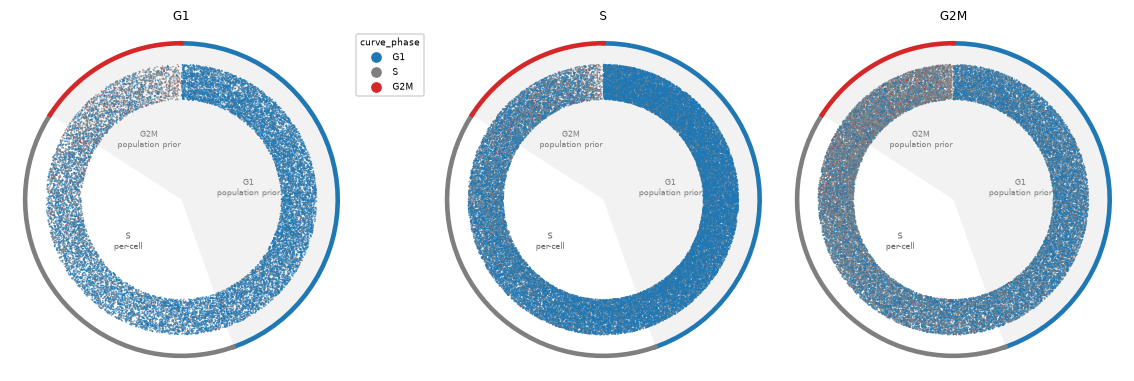

In [13]:
mt.pl.cell_cycle_clock(held, key="curve", groupby="rna_phase")
plt.show()

## Morphology features that follow the RNA clock

For each of the 1,131 imaging features, we measure how closely it follows the RNA clock with the circular-linear
correlation. It is the square root of the share of the feature's variance explained by the cosine and the sine of the
RNA position. Features can also follow the clock for technical reasons. For example, cells in crowded tiles may stain
differently and also cycle differently. So we remove the tile and the local density from both sides, the features and
the cosine and sine. {func}`~mantispy.pp.regress_out` removes the effect of the local density, from
{func}`~mantispy.tl.neighbors_local_density`, within each tile, and we then subtract each tile's mean. The last column also removes the cell area. Cells grow through the
cycle, so removing area is a stricter test, not a correction.

The IgG channels, which have no specific target, and the background of every channel are the controls.

In [14]:
img.obs["Metadata_Center_X"], img.obs["Metadata_Center_Y"] = img.obsm["spatial"][:, 0], img.obsm["spatial"][:, 1]
mt.tl.neighbors_local_density(img, by="Metadata_ImageID")
angle = 2 * np.pi * img.obs["rna_position"].to_numpy()
img.obs["log_area"] = np.log2(img.layers["raw"][:, img.var_names.get_loc("Area")])
target = ad.AnnData(
    np.column_stack([np.cos(angle), np.sin(angle)]),
    obs=img.obs[["Metadata_ImageID", "Metadata_LocalDensity", "log_area"]].copy(),
)
with warnings.catch_warnings():
    warnings.simplefilter("once")  # one sparse tile does not span the pooled density, and every call says so
    for adata in (img, target):
        mt.pp.regress_out(
            adata, keys=("Metadata_LocalDensity",), by="Metadata_ImageID", reference=None, key_added="adjusted"
        )
        mt.pp.regress_out(
            adata, keys=("Metadata_LocalDensity", "log_area"), by="Metadata_ImageID", reference=None, key_added="sized"
        )
        for layer in ("adjusted", "sized"):  # regress_out keeps each tile's own level, so take it out here
            frame = pd.DataFrame(np.asarray(adata.layers[layer], dtype=float))
            adata.layers[layer] = (
                frame - frame.groupby(adata.obs["Metadata_ImageID"].to_numpy()).transform("mean")
            ).to_numpy()


def association(features, angles):
    """Circular-linear correlation of every feature with the clock: the square root of R^2 on its cosine and sine."""
    features = np.where(np.isfinite(features), features, np.nanmedian(features, axis=0))
    features = features - features.mean(axis=0)
    basis = np.linalg.qr(angles - angles.mean(axis=0))[0]
    with np.errstate(invalid="ignore", divide="ignore"):
        return np.sqrt(((basis.T @ features) ** 2).sum(axis=0) / (features**2).sum(axis=0))


raw_r = association(np.asarray(img.X, dtype=float), target.X)
adjusted_r = association(np.asarray(img.layers["adjusted"], dtype=float), target.layers["adjusted"])
sized_r = association(np.asarray(img.layers["sized"], dtype=float), target.layers["sized"])
table = img.var[["channel"]].assign(raw=raw_r, adjusted=adjusted_r, sized=sized_r)
table["kind"] = np.where(
    img.var_names.str.startswith("Bkg_"),
    "background",
    np.where(table["channel"].str.contains("IgG"), "IgG control", "stain"),
)
change = (table[["adjusted", "sized"]].sub(table["raw"], axis=0)).abs().max(axis=1)
print(
    "largest change from adjustment, controls:",
    round(float(change[table["kind"] != "stain"].max()), 3),
    "| stains:",
    round(float(change[table["kind"] == "stain"].max()), 3),
)
table.groupby(["kind", "channel"], observed=True)[["raw", "adjusted", "sized"]].max().round(3)

<path>:12: UserWarning: regress_out: the pooled mean of ['Metadata_LocalDensity'] lies outside the range Metadata_ImageID=['C1_L2R09C02S1'] span, so those groups are corrected by extrapolating their own fit, which can leave the result more dependent on the covariate than it was. Pass reference='negcon' to anchor each group at its own controls.
  mt.pp.regress_out(


<path>:15: UserWarning: regress_out: the pooled mean of ['Metadata_LocalDensity', 'log_area'] lies outside the range Metadata_ImageID=['C1_L2R09C02S1'] span, so those groups are corrected by extrapolating their own fit, which can leave the result more dependent on the covariate than it was. Pass reference='negcon' to anchor each group at its own controls.
  mt.pp.regress_out(


<path>:12: UserWarning: regress_out: the pooled mean of ['Metadata_LocalDensity'] lies outside the range Metadata_ImageID=['C1_L2R09C02S1'] span, so those groups are corrected by extrapolating their own fit, which can leave the result more dependent on the covariate than it was. Pass reference='negcon' to anchor each group at its own controls.
  mt.pp.regress_out(
<path>:15: UserWarning: regress_out: the pooled mean of ['Metadata_LocalDensity', 'log_area'] lies outside the range Metadata_ImageID=['C1_L2R09C02S1'] span, so those groups are corrected by extrapolating their own fit, which can leave the result more dependent on the covariate than it was. Pass reference='negcon' to anchor each group at its own controls.
  mt.pp.regress_out(


largest change from adjustment, controls: 0.052 | stains: 0.16


raw  adjusted  sized
kind        channel                                          
IgG control Mouse_IgG                  0.146     0.150  0.152
            Rabbit_IgG                 0.139     0.141  0.141
background  Actin                      0.150     0.149  0.151
            Cell-Membrane              0.137     0.135  0.136
            ERK1_ERK2                  0.148     0.154  0.154
            Mitochondria               0.100     0.102  0.103
            Mouse_IgG                  0.203     0.214  0.216
            Nucleus                    0.119     0.128  0.131
            Phospho-ERK1_Phospho-ERK2  0.190     0.198  0.201
            Phospho-HSP27              0.168     0.183  0.193
            Phospho-p38                0.150     0.156  0.157
            Rabbit_IgG                 0.145     0.149  0.150
stain       Actin                      0.155     0.153  0.151
            Cell-Membrane              0.161     0.159  0.165
            ERK1_ERK2                  0.161     0.169  0.190
            Mitochondria               0.166     0.174  0.185
            Nucleus                    0.296     0.362  0.380
            Phospho-ERK1_Phospho-ERK2  0.207     0.218  0.248
            Phospho-HSP27              0.092     0.091  0.090
            Phospho-p38                0.271     0.277  0.294

The controls follow the clock before adjustment, with correlations up to about 0.2, and they still do afterwards.
Removing the tile means and the density moves a control's correlation by at most 0.05, and the largest stays at about
0.21, so the controls don't follow the clock because of where cells sit on the plate or how crowded they are.
Removing the cell area as well doesn't change that. We read their level, up to about 0.2, as the floor a feature has
to clear. Adjustment sharpens the stains instead. The Nucleus channel rises from 0.30 to 0.36 once the tile means are
removed, so differences in staining between tiles hid part of its signal. Phospho-p38 (0.28) also clears the floor,
and phospho-ERK (0.22) sits at it. Most of the best Nucleus features are intensities, which measure the DNA content
through the same stain.

In [15]:
table.sort_values("adjusted", ascending=False).head(10).round(3)

,channel,raw,adjusted,sized,kind
Nucleus_Nuclear,Nucleus,0.281,0.362,0.374,stain
Intensity_StdIntensity_Nucleus,Nucleus,0.276,0.347,0.380,stain
Intensity_MaxIntensity_Nucleus,Nucleus,0.266,0.343,0.349,stain
Nucleus_MeanIntensityOfFractionAboveThreshold_Nuclear,Nucleus,0.261,0.341,0.353,stain
Nucleus_MeanIntensityOfFractionAboveThreshold,Nucleus,0.244,0.329,0.339,stain
Intensity_IntegratedIntensity_Nucleus,Nucleus,0.263,0.327,0.333,stain
Texture_SumVariance_3_01_256_Nucleus,Nucleus,0.253,0.309,0.327,stain
Texture_SumVariance_3_03_256_Nucleus,Nucleus,0.253,0.309,0.327,stain
Texture_SumVariance_3_02_256_Nucleus,Nucleus,0.252,0.306,0.326,stain
Texture_SumVariance_3_00_256_Nucleus,Nucleus,0.252,0.306,0.326,stain


## Knockouts and the cell cycle

{func}`~mantispy.tl.composition_shift` compares each knockout's share of cells in each phase with the NTC cells
within each well. It tests the difference by relabelling guides, so the four guides of a gene are its replicates. We
run it on the RNA phases over all wells and over the held-out wells, and on the phases of the model fitted to the RNA
clock over the held-out wells.

In [16]:
held.obs["dna_phase"] = held.obs["curve_phase"].where(held.obs["curve_phase"].isin(PHASES)).astype(object)
for key, name in (("rna_phase", "rna"), ("dna_phase", "dna")):
    mt.tl.composition_shift(held, key=key, groupby="target_gene", replicate="guide", key_added=f"shift_{name}")
mt.tl.composition_shift(cells, key="rna_phase", groupby="target_gene", replicate="guide", key_added="shift_rna")
columns = ["distance", "qvalue", *PHASES]
rna_all, rna_shift, dna_shift = (
    frame.set_index("group")
    for frame in (
        cells.uns["mantispy"]["shift_rna"],
        held.uns["mantispy"]["shift_rna"],
        held.uns["mantispy"]["shift_dna"],
    )
)
print("smallest p-value the design can reach:", round(float(rna_shift["min_pvalue"].min()), 4))
pd.concat(
    {
        "RNA, all wells": rna_all[columns],
        "RNA, held-out wells": rna_shift[columns],
        "DNA, held-out wells": dna_shift[columns],
    },
    axis=1,
).round(3)

smallest p-value the design can reach: 0.0143


RNA, all wells                             RNA, held-out wells         \
             distance qvalue     G1      S    G2M            distance qvalue   
group                                                                          
IL1R1           0.010  0.693  0.004  0.006 -0.010               0.006  0.973   
GSK3B           0.007  0.693 -0.004 -0.003  0.007               0.003  0.973   
CTNNB1          0.054  0.087  0.051  0.003 -0.054               0.062  0.087   
OR1I1           0.003  0.883  0.003 -0.000 -0.003               0.014  0.508   
TGFBR2          0.025  0.087  0.024  0.001 -0.025               0.039  0.087   
SMAD7           0.002  0.943 -0.001  0.002 -0.001               0.012  0.796   

                            DNA, held-out wells                              
           G1      S    G2M            distance qvalue     G1      S    G2M  
group                                                                        
IL1R1   0.003  0.003 -0.006               0.017  0.372  0.017 -0.017 -0.000  
GSK3B  -0.001  0.003 -0.001               0.005  0.700  0.005 -0.004 -0.000  
CTNNB1  0.058  0.004 -0.062               0.026  0.372  0.026 -0.024 -0.002  
OR1I1   0.006  0.007 -0.014               0.018  0.306  0.018 -0.018 -0.000  
TGFBR2  0.033  0.006 -0.039               0.027  0.348  0.027 -0.026 -0.001  
SMAD7   0.008  0.004 -0.012               0.011  0.685  0.011 -0.009 -0.002

In [17]:
print(
    "correlation of the per-phase shifts, RNA against DNA:",
    round(
        float(
            np.corrcoef(
                rna_shift[PHASES].to_numpy().ravel(), dna_shift.loc[rna_shift.index, PHASES].to_numpy().ravel()
            )[0, 1]
        ),
        2,
    ),
)

correlation of the per-phase shifts, RNA against DNA: 0.36


On the RNA phases, the CTNNB1 and TGFBR2 knockouts move cells from G2M to G1, by about 5 and 2.5 percentage points
over all wells, and both reach a q-value of 0.087. With four guides against four NTC guides the smallest possible
p-value is 1/70, so with six knockouts no q-value can be very small. The other knockouts, OR1I1 included, barely
move, and the held-out wells alone show the same two knockouts. On the DNA phases, every knockout gains 0.5 to 3
points of G1, OR1I1 included, none has a q-value below 0.3, and the per-phase shifts correlate with the RNA shifts at
0.36. CTNNB1 and TGFBR2 still have the two largest G1 gains on the DNA phases, so the direction comes through
weakly, but the DNA phases alone would not have found either knockout.

## What you get without RNA

The table sums up what each kind of data gives on this screen.

| Data | What mantispy gives here | What it can't give here |
| --- | --- | --- |
| DNA stain only | The DNA histogram of each well, and a refusal that says why: no 4N peak, and no valley between the peaks | Phases, positions, or the phase composition of a knockout |
| DNA stain and other channels | Nothing more, since {func}`~mantispy.tl.phase_order` needs a model that passed the check | An order within a phase |
| RNA in the same cells | Phases and positions from the RNA, knockout effects on them, the features that follow the clock, and a scored check of the DNA model | Useful single-cell positions from this DNA stain, even with a calibrated model |

With a DNA stain whose intensity is proportional to the amount of DNA, such as the DAPI of the HeLa screen in
{doc}`/tutorials/single_cells/cell_cycle`, the first row gives phases, a position for every S cell and an honest
uncertainty for the rest. On this screen the DNA readout is the limit. On a new screen, look at the DNA histogram of each
well and at the check in {func}`~mantispy.tl.fit_cell_cycle` first.